Task 1: Data Acquisition and Exploration

In [ ]:
!pip install -q kagglehub scikit-image scikit-learn seaborn

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

from skimage.feature import (
    hog, local_binary_pattern, graycomatrix, graycoprops
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMAGE_SIZE = (128, 128)
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

In [ ]:
from pathlib import Path
import kagglehub

dataset_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

root = Path(dataset_path)

# Find the actual chest_xray folder
data_dir = next(
    p for p in [root] + list(root.rglob("chest_xray"))
    if (p / "train" / "NORMAL").is_dir()
    and (p / "train" / "PNEUMONIA").is_dir()
)

print("Dataset folder:", data_dir)

100%|██████████| 2.29G/2.29G [00:34<00:00, 71.3MB/s]

Extracting files...


Dataset folder: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray


In [ ]:
records = []
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for label, class_name in enumerate(CLASS_NAMES):
    for folder in data_dir.rglob(class_name):
        if folder.is_dir():
            for file in folder.rglob("*"):

                # Ignore macOS metadata files
                if file.name.startswith("._") or "__MACOSX" in file.parts:
                    continue

                if file.is_file() and file.suffix.lower() in extensions:
                    records.append({
                        "path": str(file),
                        "class_name": class_name,
                        "label": label
                    })

df = pd.DataFrame(records).drop_duplicates("path").reset_index(drop=True)

print("Valid images:", len(df))
print(df["class_name"].value_counts())

Valid images: 11712
class_name
PNEUMONIA    8546
NORMAL       3166
Name: count, dtype: int64


In [ ]:
from pathlib import Path

root = Path(dataset_path)
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

# Find the folder containing train/NORMAL or NORMAL directly.
candidates = [root] + list(root.rglob("chest_xray"))

data_dir = None

for folder in candidates:
    if (
        (folder / "train" / "NORMAL").is_dir()
        and (folder / "train" / "PNEUMONIA").is_dir()
    ) or (
        (folder / "NORMAL").is_dir()
        and (folder / "PNEUMONIA").is_dir()
    ):
        data_dir = folder
        break

if data_dir is None:
    raise FileNotFoundError("Could not find the NORMAL/PNEUMONIA folders.")

records = []

for label, class_name in enumerate(CLASS_NAMES):
    for folder in data_dir.rglob(class_name):
        if folder.is_dir():
            for file in folder.rglob("*"):
                if file.is_file() and file.suffix.lower() in extensions:
                    records.append({
                        "path": str(file),
                        "class_name": class_name,
                        "label": label
                    })

df = pd.DataFrame(records).drop_duplicates("path").reset_index(drop=True)

print("Total images:", len(df))
print(df["class_name"].value_counts())
df.head()

Total images: 17568
class_name
PNEUMONIA    12819
NORMAL        4749
Name: count, dtype: int64


,path,class_name,label
0,/root/.cache/kagglehub/datasets/paultimothymoo...,NORMAL,0
1,/root/.cache/kagglehub/datasets/paultimothymoo...,NORMAL,0
2,/root/.cache/kagglehub/datasets/paultimothymoo...,NORMAL,0
3,/root/.cache/kagglehub/datasets/paultimothymoo...,NORMAL,0
4,/root/.cache/kagglehub/datasets/paultimothymoo...,NORMAL,0


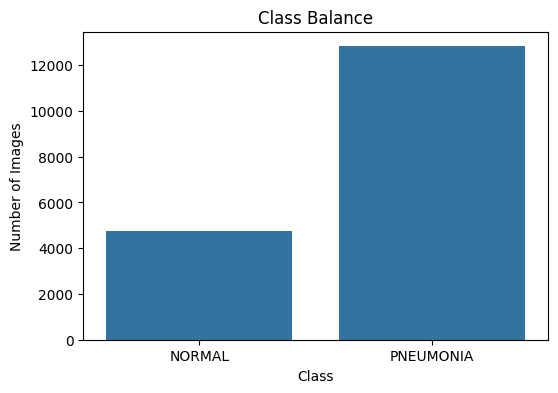

In [ ]:
counts = df["class_name"].value_counts().reindex(
    CLASS_NAMES, fill_value=0
)

plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values)

plt.title("Class Balance")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

In [ ]:
# Remove macOS metadata files from the existing DataFrame
df = df[
    ~df["path"].str.contains(r"/__MACOSX/|/\._", regex=True)
].copy()

df = df.reset_index(drop=True)

print("Remaining images:", len(df))
print("Class counts:")
print(df["class_name"].value_counts())

Remaining images: 11712
Class counts:
class_name
PNEUMONIA    8546
NORMAL       3166
Name: count, dtype: int64


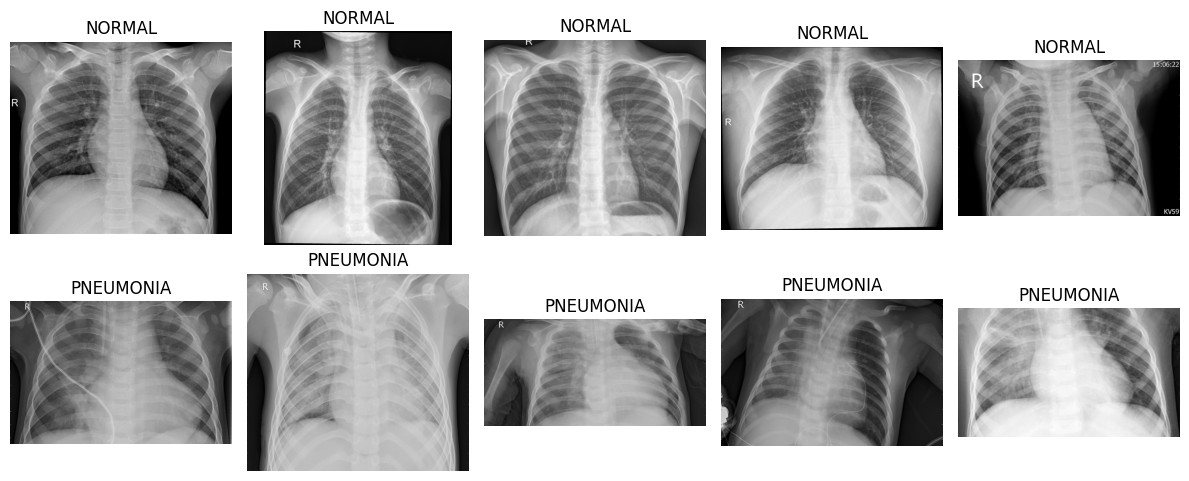

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for row, class_name in enumerate(CLASS_NAMES):
    samples = df[df["class_name"] == class_name].sample(
        n=min(5, (df["class_name"] == class_name).sum()),
        random_state=SEED
    )

    col = 0

    for _, item in samples.iterrows():
        try:
            with Image.open(item["path"]) as image:
                axes[row, col].imshow(
                    image.convert("L"),
                    cmap="gray"
                )

            axes[row, col].set_title(class_name)
            axes[row, col].axis("off")
            col += 1

        except Exception as e:
            print("Skipping invalid file:", item["path"])

    for j in range(col, 5):
        axes[row, j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 8198
Validation images: 1757
Testing images: 1757


In [ ]:
def load_image(path, grayscale=False):
    mode = "L" if grayscale else "RGB"

    with Image.open(path) as image:
        image = image.convert(mode)
        image = image.resize(IMAGE_SIZE)
        array = np.asarray(image, dtype=np.float32) / 255.0

    return array

In [ ]:
def extract_features(path):
    image = load_image(path, grayscale=True)

    # HOG: edges and gradient directions
    hog_features = hog(
        image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        feature_vector=True
    )

    # LBP: local texture patterns
    lbp = local_binary_pattern(
        (image * 255).astype(np.uint8),
        P=8,
        R=1,
        method="uniform"
    )

    lbp_hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, 12),
        range=(0, 11),
        density=True
    )

    # GLCM: relationships between neighbouring pixels
    quantized = np.clip(
        (image * 15).astype(np.uint8), 0, 15
    )

    glcm = graycomatrix(
        quantized,
        distances=[1, 3],
        angles=[0, np.pi / 4],
        levels=16,
        symmetric=True,
        normed=True
    )

    glcm_features = []

    for prop in [
        "contrast", "dissimilarity", "homogeneity",
        "energy", "correlation", "ASM"
    ]:
        glcm_features.extend(
            graycoprops(glcm, prop).ravel()
        )

    return np.concatenate([
        hog_features,
        lbp_hist,
        np.asarray(glcm_features)
    ])

In [ ]:
def prepare_features(part, name):
    features = []

    for i, path in enumerate(part["path"], start=1):
        features.append(extract_features(path))

        if i % 500 == 0:
            print(f"{name}: {i} images processed")

    X = np.vstack(features)
    y = part["label"].to_numpy(dtype=np.int32)

    return X, y


X_train_features, y_train = prepare_features(
    train_df, "Training"
)

X_val_features, y_val = prepare_features(
    val_df, "Validation"
)

X_test_features, y_test = prepare_features(
    test_df, "Testing"
)

print("Feature matrix:", X_train_features.shape)

Training: 500 images processed
Training: 1000 images processed
Training: 1500 images processed
Training: 2000 images processed
Training: 2500 images processed
Training: 3000 images processed
Training: 3500 images processed
Training: 4000 images processed
Training: 4500 images processed
Training: 5000 images processed
Training: 5500 images processed
Training: 6000 images processed
Training: 6500 images processed
Training: 7000 images processed
Training: 7500 images processed
Training: 8000 images processed
Validation: 500 images processed
Validation: 1000 images processed
Validation: 1500 images processed
Testing: 500 images processed
Testing: 1000 images processed
Testing: 1500 images processed
Feature matrix: (8198, 1799)


In [ ]:
def decode_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.float32)


def make_dataset(part, training=False):
    paths = part["path"].to_numpy()
    labels = part["label"].to_numpy(dtype=np.float32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            min(len(part), 2000),
            seed=SEED
        )

    dataset = dataset.map(
        decode_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(32).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

In [ ]:
from tensorflow.keras import layers, models

cnn = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(
        32, 3, activation="relu", padding="same"
    ),
    layers.MaxPooling2D(),

    layers.Conv2D(
        64, 3, activation="relu", padding="same"
    ),
    layers.MaxPooling2D(),

    layers.Conv2D(
        128, 3, activation="relu", padding="same"
    ),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
counts = np.bincount(y_train, minlength=2)
total = counts.sum()

class_weights = {
    i: total / (2 * max(counts[i], 1))
    for i in range(2)
}

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping]
)

Epoch 1/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 434s 2s/step - accuracy: 0.8881 - auc: 0.9563 - loss: 0.2706 - val_accuracy: 0.9351 - val_auc: 0.9870 - val_loss: 0.1546
Epoch 2/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 432s 2s/step - accuracy: 0.9427 - auc: 0.9834 - loss: 0.1611 - val_accuracy: 0.9550 - val_auc: 0.9914 - val_loss: 0.1096
Epoch 3/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 431s 2s/step - accuracy: 0.9530 - auc: 0.9907 - loss: 0.1200 - val_accuracy: 0.9596 - val_auc: 0.9934 - val_loss: 0.1000
Epoch 4/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 457s 2s/step - accuracy: 0.9619 - auc: 0.9934 - loss: 0.1010 - val_accuracy: 0.9539 - val_auc: 0.9918 - val_loss: 0.1335
Epoch 5/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 436s 2s/step - accuracy: 0.9663 - auc: 0.9951 - loss: 0.0861 - val_accuracy: 0.9664 - val_auc: 0.9946 - val_loss: 0.0932
Epoch 6/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 468s 2s/step - accuracy: 0.9740 - auc: 0.9966 - loss: 0.0706 - val_accuracy: 0.9727 - val_auc: 0.9948 - val_loss: 0.0780
Epoch 7/10
257/257 ━━━━━━━━━━━━━━━

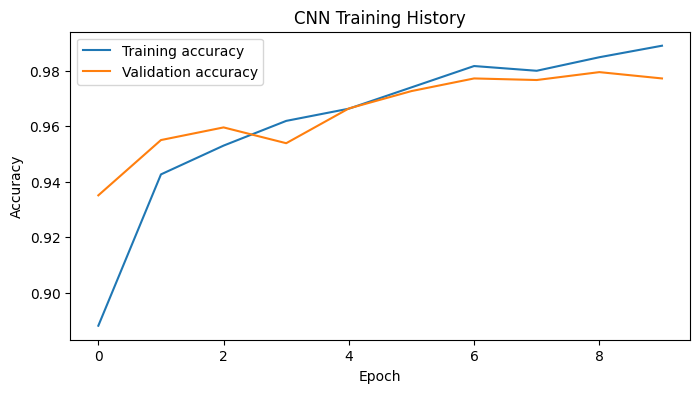

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(
    history.history["accuracy"],
    label="Training accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training History")
plt.legend()
plt.show()

In [ ]:
cnn.save("/content/chest_xray_cnn.keras")

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        probability=True,
        random_state=SEED
    )
)

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

models_to_train = {
    "SVM": svm,
    "Random Forest": rf
}

trained_models = {}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

for name, model in models_to_train.items():
    print("\nTraining:", name)

    scores = cross_val_score(
        model,
        X_train_features,
        y_train,
        cv=cv,
        scoring="f1"
    )

    print("Mean 3-fold CV F1-score:", scores.mean())

    model.fit(X_train_features, y_train)
    trained_models[name] = model


Training: SVM
Mean 3-fold CV F1-score: 0.984331919461176

Training: Random Forest
Mean 3-fold CV F1-score: 0.9808848233082029


In [ ]:
def evaluate_model(name, y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)

    print("\nModel:", name)

    print("Accuracy:",
          accuracy_score(y_true, predictions))

    print("Precision:",
          precision_score(
              y_true, predictions, zero_division=0
          ))

    print("Recall:",
          recall_score(
              y_true, predictions, zero_division=0
          ))

    print("F1-score:",
          f1_score(
              y_true, predictions, zero_division=0
          ))

    print("AUROC:",
          roc_auc_score(y_true, probabilities))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predictions,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{name} Confusion Matrix")
    plt.show()

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "AUROC": roc_auc_score(y_true, probabilities)
    }

In [ ]:
results = []

# CNN predictions
cnn_probabilities = np.concatenate([
    cnn.predict(images, verbose=0).ravel()
    for images, labels in test_ds
])

results.append(
    evaluate_model(
        "CNN",
        y_test,
        cnn_probabilities
    )
)

# SVM and Random Forest predictions
for name, model in trained_models.items():
    probabilities = model.predict_proba(
        X_test_features
    )[:, 1]

    results.append(
        evaluate_model(
            name,
            y_test,
            probabilities
        )
    )

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["F1-score", "AUROC"],
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "AUROC": "{:.4f}"
    })
)

results_df.to_csv(
    "/content/model_comparison.csv",
    index=False
)

print("Comparison saved successfully.")

,Model,Accuracy,Precision,Recall,F1-score,AUROC
0,SVM,0.9852,0.9906,0.9891,0.9899,0.9968
1,Random Forest,0.9812,0.9822,0.9922,0.9872,0.9977
2,CNN,0.9761,0.9726,0.9953,0.9838,0.9961


Comparison saved successfully.
